In [1]:
!pip install -q ultralytics fastapi uvicorn python-multipart nest-asyncio

In [2]:
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt

from ultralytics import YOLO
from collections import Counter

print("VisionPort Libraries Imported Successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
VisionPort Libraries Imported Successfully!


In [3]:
print("VISIONPORT GPU CHECK")

if torch.cuda.is_available():

    print("GPU Status: Available")
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("CUDA Version:", torch.version.cuda)

else:

    print("GPU Not Available")
    print("Please enable T4 GPU")

VISIONPORT GPU CHECK
GPU Status: Available
GPU Name: Tesla T4
CUDA Version: 13.0


In [4]:
model = YOLO("yolov8n.pt")

device = 0 if torch.cuda.is_available() else "cpu"

print("VisionPort Model Loaded!")
print("Model: YOLOv8n")
print("Device:", device)

VisionPort Model Loaded!
Model: YOLOv8n
Device: 0


In [5]:
from google.colab import files

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

print("Uploaded Image:", image_path)

Saving download.jpg to download.jpg
Uploaded Image: download.jpg


In [6]:
results = model.predict(
    source=image_path,
    conf=0.25,
    device=device,
    save=True
)

print("Object Detection Completed!")


image 1/1 /content/download.jpg: 352x640 14 cars, 4 buss, 3 trucks, 7.1ms
Speed: 146.4ms preprocess, 7.1ms inference, 21.6ms postprocess per image at shape (1, 3, 352, 640)
Results saved to /content/runs/detect/predict
Object Detection Completed!


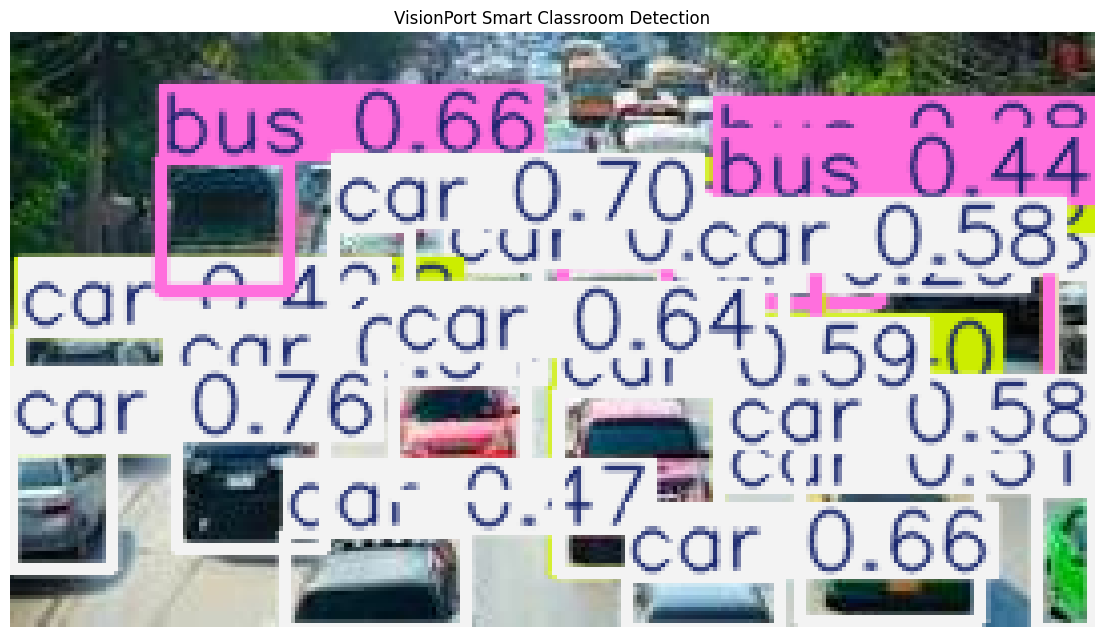

In [7]:
output_image = results[0].plot()

output_image = cv2.cvtColor(
    output_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(14, 8))

plt.imshow(output_image)
plt.axis("off")

plt.title("VisionPort Smart Classroom Detection")

plt.show()

In [8]:
object_counts = Counter()

for box in results[0].boxes:

    class_id = int(box.cls[0])

    object_name = model.names[class_id]

    object_counts[object_name] += 1

print("VISIONPORT OBJECT ANALYTICS")

print("Total Objects:", sum(object_counts.values()))

for name, count in object_counts.items():

    print(name, ":", count)

VISIONPORT OBJECT ANALYTICS
Total Objects: 21
car : 14
bus : 4
truck : 3


In [9]:
print("OBJECT CONFIDENCE REPORT")

for box in results[0].boxes:

    class_id = int(box.cls[0])

    name = model.names[class_id]

    confidence = float(box.conf[0]) * 100

    print(
        name,
        "Confidence:",
        round(confidence, 2),
        "%"
    )

OBJECT CONFIDENCE REPORT
car Confidence: 75.64 %
car Confidence: 70.14 %
bus Confidence: 66.15 %
car Confidence: 65.56 %
car Confidence: 63.99 %
car Confidence: 58.5 %
car Confidence: 58.34 %
car Confidence: 57.54 %
car Confidence: 53.98 %
car Confidence: 51.08 %
car Confidence: 47.22 %
bus Confidence: 43.7 %
car Confidence: 41.84 %
truck Confidence: 39.89 %
truck Confidence: 37.88 %
car Confidence: 33.42 %
bus Confidence: 30.74 %
car Confidence: 29.43 %
truck Confidence: 28.8 %
bus Confidence: 27.73 %
car Confidence: 27.73 %


In [10]:
from fastapi import FastAPI, UploadFile, File, HTTPException

from PIL import Image

from io import BytesIO

import uvicorn
import nest_asyncio
import threading
import time

app = FastAPI(
    title="VisionPort AI API",
    description="Smart Classroom Object Detection",
    version="1.0"
)

print("VisionPort FastAPI Initialized!")

VisionPort FastAPI Initialized!


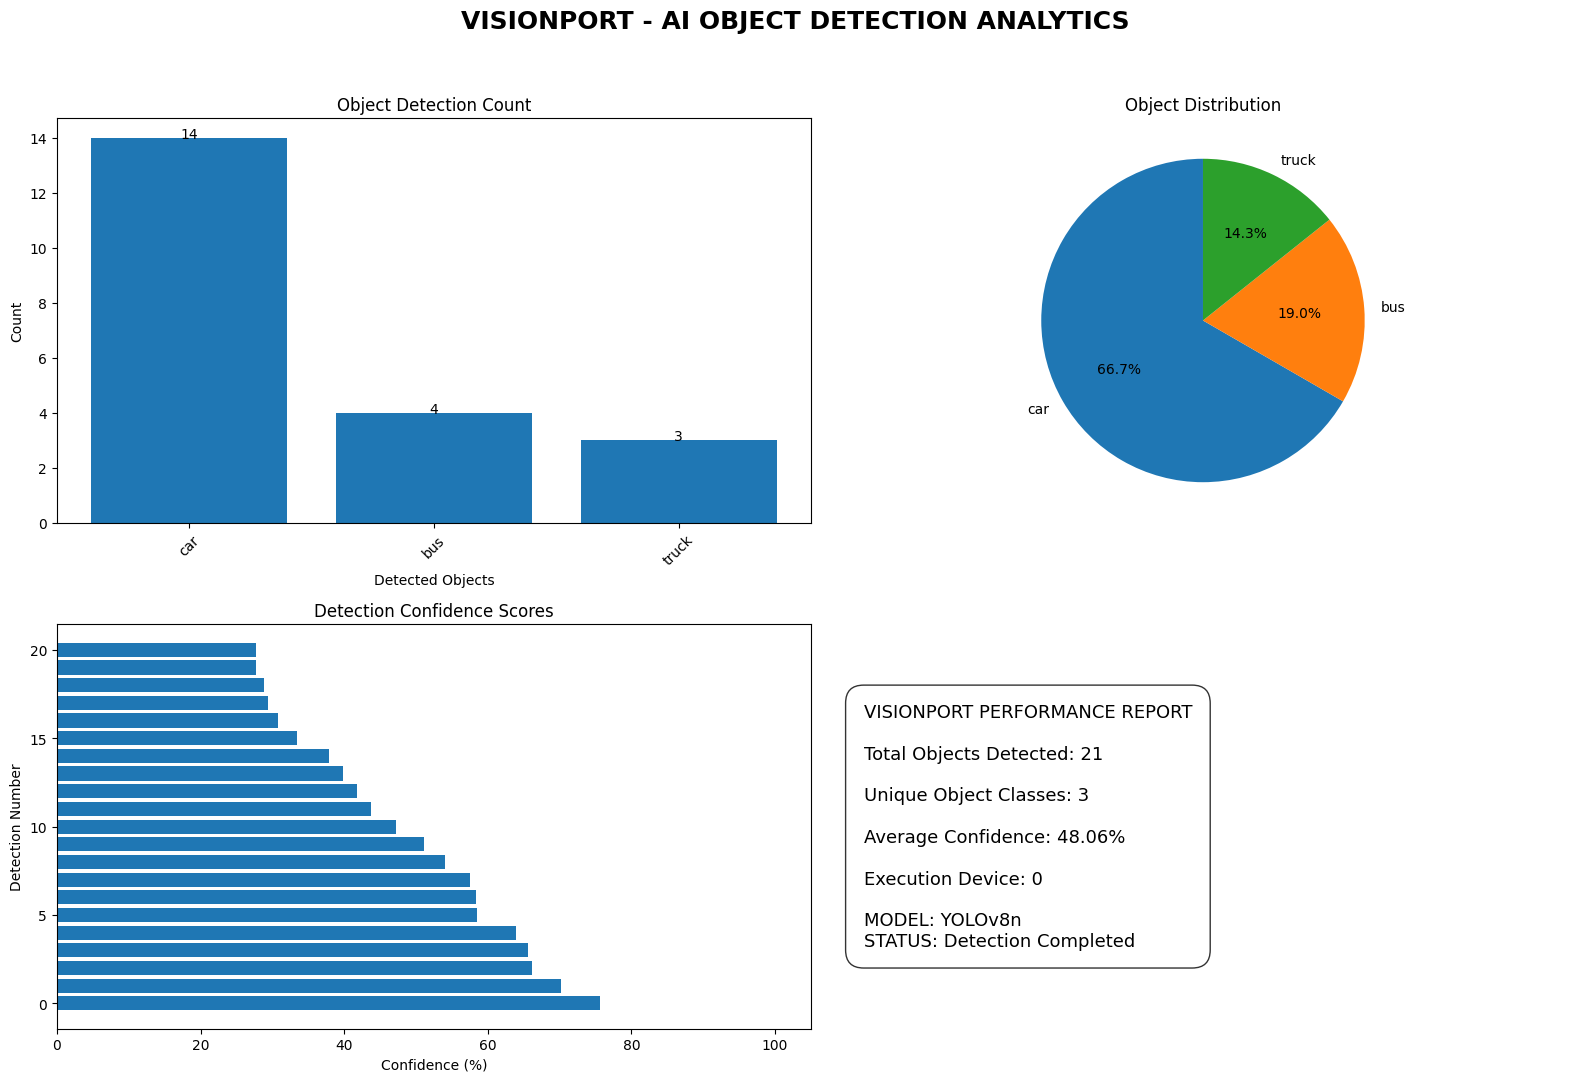

VisionPort Analytics Dashboard Generated!
Total Objects: 21
Average Confidence: 48.06 %


In [16]:
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter

# Extract detected object information
object_names = []
confidence_scores = []

for box in results[0].boxes:

    class_id = int(box.cls[0])

    name = model.names[class_id]

    confidence = float(box.conf[0]) * 100

    object_names.append(name)

    confidence_scores.append(confidence)


# Count objects
object_counts = Counter(object_names)

labels = list(object_counts.keys())
values = list(object_counts.values())

total_objects = sum(values)

average_confidence = (
    np.mean(confidence_scores)
    if confidence_scores else 0
)

# Create dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

fig.suptitle(
    "VISIONPORT - AI OBJECT DETECTION ANALYTICS",
    fontsize=18,
    fontweight="bold"
)


# 1. Object Detection Bar Graph
axes[0, 0].bar(
    labels,
    values
)

axes[0, 0].set_title("Object Detection Count")
axes[0, 0].set_xlabel("Detected Objects")
axes[0, 0].set_ylabel("Count")
axes[0, 0].tick_params(axis="x", rotation=45)

for i, value in enumerate(values):
    axes[0, 0].text(i, value, str(value), ha="center")


# 2. Object Distribution Pie Chart
axes[0, 1].pie(
    values,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90
)

axes[0, 1].set_title("Object Distribution")


# 3. Confidence Score Graph
axes[1, 0].barh(
    range(len(confidence_scores)),
    confidence_scores
)

axes[1, 0].set_title("Detection Confidence Scores")
axes[1, 0].set_xlabel("Confidence (%)")
axes[1, 0].set_ylabel("Detection Number")
axes[1, 0].set_xlim(0, 105)


# 4. Object Summary Dashboard
axes[1, 1].axis("off")

summary = (
    "VISIONPORT PERFORMANCE REPORT\n\n"
    f"Total Objects Detected: {total_objects}\n\n"
    f"Unique Object Classes: {len(labels)}\n\n"
    f"Average Confidence: {average_confidence:.2f}%\n\n"
    f"Execution Device: {device}\n\n"
    "MODEL: YOLOv8n\n"
    "STATUS: Detection Completed"
)

axes[1, 1].text(
    0.05,
    0.5,
    summary,
    fontsize=13,
    verticalalignment="center",
    bbox=dict(
        boxstyle="round",
        pad=1,
        facecolor="white",
        alpha=0.8
    )
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    "VisionPort_Analytics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("VisionPort Analytics Dashboard Generated!")
print("Total Objects:", total_objects)
print("Average Confidence:", round(average_confidence, 2), "%")

In [11]:
@app.get("/")
def home():

    return {
        "project": "VisionPort",
        "status": "Running",
        "model": "YOLOv8n",
        "backend": "FastAPI",
        "device": str(device)
    }

In [12]:
@app.get("/health")
def health():

    return {
        "API": "Healthy",
        "Model": "Loaded",
        "GPU": torch.cuda.is_available()
    }

In [13]:
@app.post("/detect")
async def detect(file: UploadFile = File(...)):

    if file.content_type not in [
        "image/jpeg",
        "image/png",
        "image/webp"
    ]:

        raise HTTPException(
            status_code=400,
            detail="Invalid image format"
        )

    contents = await file.read()

    image = Image.open(
        BytesIO(contents)
    ).convert("RGB")

    results = model.predict(
        source=np.array(image),
        conf=0.25,
        device=device,
        verbose=False
    )

    detections = []
    counts = Counter()

    for box in results[0].boxes:

        class_id = int(box.cls[0])

        name = model.names[class_id]

        confidence = float(box.conf[0]) * 100

        counts[name] += 1

        detections.append({

            "object": name,

            "confidence": round(confidence, 2),

            "bounding_box": [
                round(float(x), 2)
                for x in box.xyxy[0].tolist()
            ]

        })

    return {

        "project": "VisionPort",

        "status": "success",

        "model": "YOLOv8n",

        "inference_device": str(device),

        "total_objects": len(detections),

        "object_summary": dict(counts),

        "detections": detections

    }

print("Detection API Created Successfully!")

Detection API Created Successfully!


In [14]:
nest_asyncio.apply()

def start_server():

    uvicorn.run(
        app,
        host="0.0.0.0",
        port=8000,
        log_level="warning"
    )

server_thread = threading.Thread(
    target=start_server,
    daemon=True
)

server_thread.start()

time.sleep(3)

print("VisionPort API Server Started!")

VisionPort API Server Started!


In [15]:
from google.colab.output import eval_js

public_url = eval_js(
    "google.colab.kernel.proxyPort(8000)"
)

print("VISIONPORT API:", public_url)

print("SWAGGER DOCUMENTATION:")

print(public_url + "/docs")

VISIONPORT API: https://8000-gpu-t4-s-usw1b2-y7odr5m4g0dx-b.us-west1.prod.r.colab.dev
SWAGGER DOCUMENTATION:
https://8000-gpu-t4-s-usw1b2-y7odr5m4g0dx-b.us-west1.prod.r.colab.dev/docs
